# 06 — Теоретические эталоны и практические результаты

Сопоставляем сообщение руководителя (`mu_info/info.txt`, `mu_H_1.xlsx`) с **уже сохранёнными** результатами проекта. Обучение и симуляция не запускаются.

Здесь три разных источника: **формулы**, **кэшированные числа Excel**, **оценки обученной стратегии**. Вычисленный по формуле столбец для N из конфига не является столбцом Excel. Сравнение разных H показывает согласованность с предельным случаем, но не измеряет ошибку алгоритма при одном H.

Порядок: параметры → аналитика → проверка Excel → влияние сетки → стоимость → границы → выводы. Все ячейки можно выполнить последовательно из корня проекта или `notebooks/`.

In [1]:
from pathlib import Path
import json
import sys
import zipfile
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import norm, t
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/config.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из каталога проекта или notebooks/")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from infrastructure.identity import node_key

plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2, "legend.frameon": False})
pd.set_option("display.max_columns", 18)

## Параметры и происхождение данных

`N` читается из `experiment.json`: это число **положительных** дат решения; вместе с нулём дат N+1. `n_fine` — отдельная сетка наблюдений/сигнатур.

Для другого расчёта согласованно измените RUN_ID и каталог готовых таблиц BOUNDARY_DIR. Excel необязателен: без локального файла остальные разделы работают. Экспорт выключен; графики и таблицы остаются в ноутбуке.

In [2]:
RUN_ID = "daily21_21_train20k_test20k_v1"
TUNING_ID = "separate_windows_validation64_v2"
RUN_DIR = ROOT / "result_optimal_stopping/runs" / RUN_ID
BOUNDARY_DIR = ROOT / "result_optimal_stopping/synthetic_tuning" / TUNING_ID
INFO_DIR = ROOT.parent / "mu_info"
ALPHAS = (0.1,)
H_NEAR_ONE = (0.90, 0.96, 0.98)
CONFIDENCE = 0.95
SAVE_ARTIFACTS = False
OUT = RUN_DIR / "analysis/theory_comparison"

manifest = json.loads((RUN_DIR / "experiment.json").read_text())
cfg = manifest["config"]
T, N = float(cfg["T"]), int(cfg["n_exercise"])
if T != 1:
    raise ValueError("Эталоны ниже выведены для T=1; требуется явное масштабирование")
if N < 2:
    raise ValueError("Для рассматриваемых границ требуется N >= 2")
frozen_path = BOUNDARY_DIR / "frozen.json"
if frozen_path.exists():
    frozen = json.loads(frozen_path.read_text())
    if Path(frozen["run_dir"]).name != RUN_ID or int(frozen["D"]) != N:
        raise ValueError("Таблицы границ и выбранный прогон относятся к разным конфигурациям")
frames = {}
for alpha in ALPHAS:
    path = BOUNDARY_DIR / f"boundaries_alpha{alpha:g}.csv"
    frame = pd.read_csv(path).sort_values("H")
    if (not np.allclose(frame["alpha"], alpha)
        or not np.allclose(frame["confidence"], CONFIDENCE)
        or not frame["gain_mode"].eq("paired").all()
        or not np.allclose(frame["H"], cfg["H_grid"])):
        raise ValueError(f"Параметры таблицы не совпадают: {path}")
    frames[alpha] = frame

display(pd.DataFrame([{
    "RUN_ID": RUN_ID, "N intervals": N, "dates incl. zero": N + 1,
    "first exercise": 1/N, "n_fine": cfg["n_fine"],
    "train": cfg["M_train"], "test": cfg["M_test"], "T": T,
}]))
print("Практические границы:", BOUNDARY_DIR)
print("Excel:", INFO_DIR / "mu_H_1.xlsx")

def save_figure(fig, name):
    if SAVE_ARTIFACTS:
        OUT.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUT / f"{name}.png", dpi=160, bbox_inches="tight")

def save_table(table, name):
    if SAVE_ARTIFACTS:
        OUT.mkdir(parents=True, exist_ok=True)
        table.to_csv(OUT / f"{name}.csv", index=False)

,RUN_ID,N intervals,dates incl. zero,first exercise,n_fine,train,test,T
0,daily21_21_train20k_test20k_v1,21,22,0.047619,21,20000,20000,1.0


Практические границы: /Users/armkilikia/optimal-stopping-fbm/result_optimal_stopping/synthetic_tuning/separate_windows_validation64_v2
Excel: /Users/armkilikia/mu_info/mu_H_1.xlsx


## Аналитические эталоны

При H=1/2 теорема об остановке даёт $V(\mu,1/2)=\max(0,\mu)$: обе точные границы равны нулю.

При H=1 имеем $X_t=(\mu+\xi)t$, $\xi\sim N(0,1)$. В первый положительный момент наклон уже известен. Если решение в нуле — продолжать, оптимально остановиться в $1/N$ при отрицательном наклоне и в 1 при положительном. Поэтому

$$f(\mu)=\mu\Phi(\mu)+\varphi(\mu),\quad
C_N(\mu)=\frac{\mu}{N}+\left(1-\frac1N\right)f(\mu),\quad
V_N(\mu,1)=\max\{0,C_N(\mu)\}.$$

Excel считает $C_N$, которое может быть отрицательным. В полной задаче разрешён отказ в нуле. Точная левая граница — единственный корень $C_N=0$; правая равна $+\infty$ при N≥2.

В непрерывном времени супремум равен f. При тривиальной $\mathcal F_0$ стратегия «остановиться в нуле в зависимости от ξ» недопустима; значение приближается остановкой в δ>0 при отрицательном наклоне, δ↓0. Если ξ известна уже в нуле, супремум достигается. Это различие фильтраций важно для формулировки руководителя.

Практические границы определяем на всей оси: $\mu_1^\varepsilon=\sup\{\mu:V\le\varepsilon\}$ и $\mu_2^\varepsilon=\inf\{\mu:V-\mu\le\varepsilon\}$. При H=1/2 для фиксированного ε они равны ε и −ε; при относительном допуске ε=αV(0)=0 используем аналитический ноль.

In [3]:
def f(mu):
    mu = np.asarray(mu, dtype=float)
    return mu * norm.cdf(mu) + norm.pdf(mu)

def continuation_h1(mu, n):
    return np.asarray(mu) / n + (1 - 1/n) * f(mu)

def value_h1(mu, n):
    return np.maximum(0, continuation_h1(mu, n))

def value_brownian(mu):
    return np.maximum(0, np.asarray(mu, dtype=float))

def root_increasing(fun, target):
    lo, hi = -1., 1.
    for _ in range(60):
        if fun(lo) <= target <= fun(hi):
            return brentq(lambda x: float(fun(x) - target), lo, hi)
        lo *= 2
        hi *= 2
    raise ValueError("Не удалось заключить корень в интервал")

def exact_left(n):
    return root_increasing(lambda x: continuation_h1(x, n), 0.)

def epsilon_boundaries(n, epsilon):
    if not np.isfinite(epsilon) or epsilon <= 0:
        raise ValueError("Для конечной правой ε-границы требуется epsilon > 0")
    left = root_increasing(lambda x: value_h1(x, n), epsilon)
    right = -root_increasing(lambda x: value_h1(-x, n) + x, epsilon)
    return left, right

analytic = pd.DataFrame([
    {"case": "H=1/2, any N", "V(0)": 0., "exact left": 0., "exact right": 0.},
    {"case": f"H=1, N={N} (formula)", "V(0)": float(value_h1(0, N)),
     "exact left": exact_left(N), "exact right": np.inf},
    {"case": "H=1, continuous supremum", "V(0)": float(f(0)),
     "exact left": -np.inf, "exact right": np.inf},
])
display(analytic)

,case,V(0),exact left,exact right
0,"H=1/2, any N",0.000000,0.00000,0.0
1,"H=1, N=21 (formula)",0.379945,-1.17671,inf
2,"H=1, continuous supremum",0.398942,-inf,inf


## Проверка Excel руководителя

Читаем сохранённые численные значения без пересчёта Excel и без зависимости от openpyxl. Проверяем заголовки и каждый столбец C–F относительно C_N. Заголовки N берутся из самого файла, а не из нашего конфига. Отрицательные C_N отдельно показывают необходимость максимума с нулём. Текст сообщения обрывается; случай H=0 в нём фактически не разобран.

In [4]:
xlsx_path = INFO_DIR / "mu_H_1.xlsx"
excel_check = pd.DataFrame()
if xlsx_path.exists():
    ns = {"s": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
    with zipfile.ZipFile(xlsx_path) as archive:
        sheet = ET.fromstring(archive.read("xl/worksheets/sheet1.xml"))
        cached = {c.attrib["r"]: float(c.find("s:v", ns).text)
                  for c in sheet.findall(".//s:sheetData/s:row/s:c", ns)
                  if c.find("s:v", ns) is not None and c.get("t") not in ("s", "e", "b")}
    excel_ns = {col: int(cached[f"{col}1"]) for col in "CDEF"}
    rows = []
    for col, n in excel_ns.items():
        indices = sorted(int(key[1:]) for key in cached
                         if key.startswith(col) and key[1:].isdigit()
                         and int(key[1:]) >= 2 and f"A{key[1:]}" in cached)
        mu = np.array([cached[f"A{i}"] for i in indices])
        observed = np.array([cached[f"{col}{i}"] for i in indices])
        rows.append({"Excel column": col, "N from Excel": n, "rows": len(indices),
                     "max |Excel - C_N|": np.max(np.abs(observed - continuation_h1(mu, n))),
                     "negative C_N rows": int(np.sum(observed < 0))})
    excel_check = pd.DataFrame(rows)
    display(excel_check)
    print(f"N={N} из нашего конфига; столбцы Excel: {list(excel_ns.values())}")
else:
    print("Excel отсутствует; проверка пропущена. Аналитика ниже вычисляется независимо.")

,Excel column,N from Excel,rows,max |Excel - C_N|,negative C_N rows
0,C,2,201,4.440892e-16,58
1,D,10,201,4.440892e-16,37
2,E,30,201,4.440892e-16,24
3,F,100,201,4.440892e-16,10


N=21 из нашего конфига; столбцы Excel: [2, 10, 30, 100]


## Влияние дискретизации при H=1

Сплошные линии — V_N с возможностью отказа в нуле. Пунктир — непрерывный супремум f. Точная правая граница бесконечна при каждом N≥2; маленький положительный выигрыш над удержанием не становится тождественным нулём.

,N,source,V0,exact left,exact right
0,2,analytical formula,0.199471,-0.276030,inf
1,10,analytical formula,0.359048,-0.901462,inf
2,21,analytical formula,0.379945,-1.176710,inf
3,30,analytical formula,0.385644,-1.305354,inf
4,100,analytical formula,0.394953,-1.720783,inf


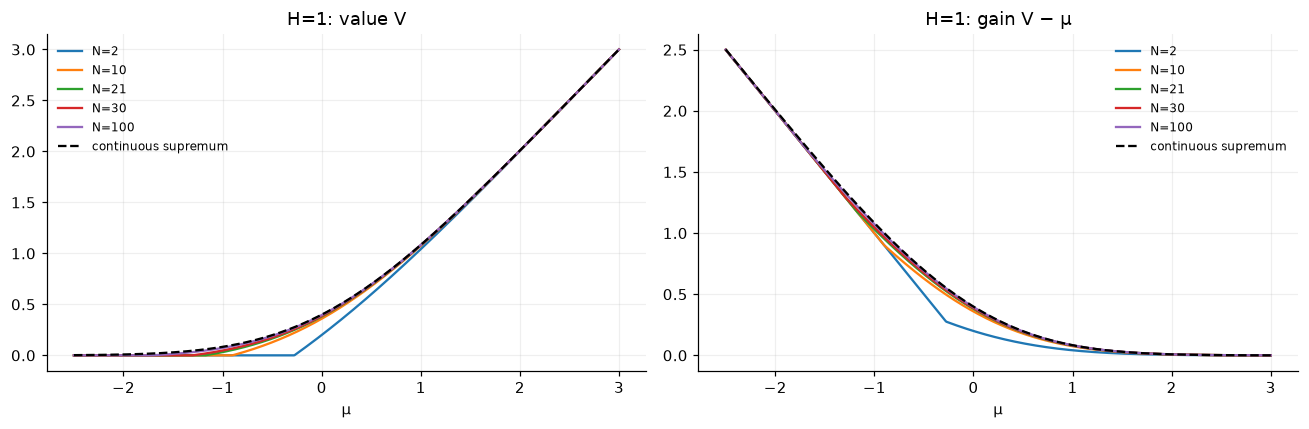

In [5]:
mu_plot = np.linspace(-2.5, 3, 700)
n_values = sorted({2, 10, 30, 100, N})
grid_comparison = pd.DataFrame([
    {"N": n, "source": "analytical formula", "V0": float(value_h1(0, n)),
     "exact left": exact_left(n), "exact right": np.inf} for n in n_values
])
display(grid_comparison)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for n in n_values:
    axes[0].plot(mu_plot, value_h1(mu_plot, n), label=f"N={n}")
    axes[1].plot(mu_plot, value_h1(mu_plot, n)-mu_plot, label=f"N={n}")
axes[0].plot(mu_plot, f(mu_plot), "k--", label="continuous supremum")
axes[1].plot(mu_plot, f(mu_plot)-mu_plot, "k--", label="continuous supremum")
for ax, title in zip(axes, ["H=1: value V", "H=1: gain V − μ"]):
    ax.set(xlabel="μ", title=title)
    ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "discretization")
plt.show()

## Стоимость сохранённой стратегии: H=1/2 и H около 1

Загружаем готовые узлы только для выбранных H через идентификаторы проекта. Пропущенные и незавершённые узлы не соединяем линией. Полоса — поточечный Student-интервал средней награды стратегии, не интервал истинного оптимума и не одновременная полоса.

При H=1/2 есть эталон **для того же H**. При H<1 сравнение с H=1 — ориентир для предельного поведения. Знак разности не доказывает монотонность по H. Даже в первом случае расхождение со стоимостью оптимума включает возможную неоптимальность стратегии; отдельно остаётся ограничение исходного выбора действия в нуле.

Загружено узлов: 5204 Отсутствует файлов: 0


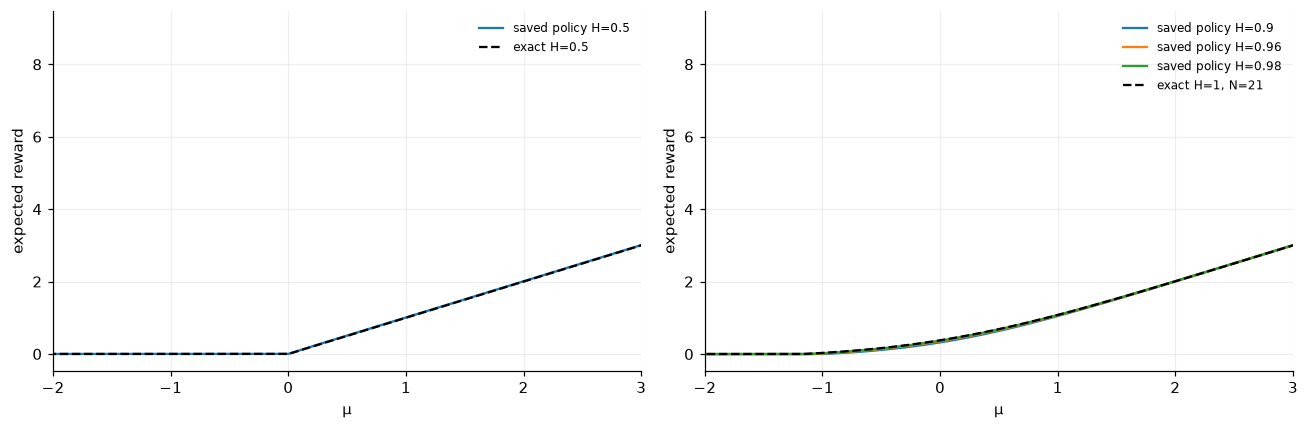

,H data,H benchmark,"nodes in [-2,3]",saved V0,benchmark V0,mean signed difference,RMSE difference
0,0.50,0.5,501,0.001966,0.000000,0.004424,0.005815
1,0.90,1.0,501,0.322207,0.379945,-0.022212,0.031783
2,0.96,1.0,501,0.355136,0.379945,-0.009859,0.014334
3,0.98,1.0,501,0.369870,0.379945,-0.002561,0.006002


In [6]:
node_rows = []
missing_nodes = []
selected_h = (0.5, *H_NEAR_ONE)
for h in selected_h:
    if not any(np.isclose(h, x) for x in cfg["H_grid"]):
        raise ValueError(f"H={h} отсутствует в сетке выбранного прогона")
    for mu in cfg["mu_grid"]:
        path = RUN_DIR / "nodes" / f"{node_key(h, mu)}.json"
        if not path.exists():
            missing_nodes.append((h, mu))
            continue
        row = json.loads(path.read_text())
        if not np.isclose(row["H"], h) or not np.isclose(row["mu"], mu):
            raise ValueError(f"Координаты узла не совпадают: {path}")
        if row.get("complete") and row["n"] >= 2:
            node_rows.append(row)
nodes = pd.DataFrame(node_rows)
if nodes.empty:
    raise ValueError("Нет завершённых узлов для сравнения стоимости")
nodes["half_width"] = t.ppf((1 + CONFIDENCE)/2, nodes["n"]-1) * nodes["SE"]
print("Загружено узлов:", len(nodes), "Отсутствует файлов:", len(missing_nodes))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for h in selected_h:
    view = nodes[np.isclose(nodes.H, h)].set_index("mu").reindex(cfg["mu_grid"])
    theory = value_brownian(view.index) if h == .5 else value_h1(view.index, N)
    ax = axes[0] if h == .5 else axes[1]
    line, = ax.plot(view.index, view.V, label=f"saved policy H={h:g}")
    ax.fill_between(view.index, view.V-view.half_width, view.V+view.half_width,
                    color=line.get_color(), alpha=.12)
axes[0].plot(mu_plot, value_brownian(mu_plot), "k--", label="exact H=0.5")
axes[1].plot(mu_plot, value_h1(mu_plot, N), "k--", label=f"exact H=1, N={N}")
for ax in axes:
    ax.set(xlabel="μ", ylabel="expected reward", xlim=(-2, 3))
    ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "saved_values")
plt.show()

value_rows = []
for h in selected_h:
    view = nodes[np.isclose(nodes.H, h)].copy()
    view = view[view.mu.between(-2, 3)]
    if view.empty:
        continue
    theory = value_brownian(view.mu) if h == .5 else value_h1(view.mu, N)
    difference = view.V.to_numpy() - theory
    zero = view[np.isclose(view.mu, 0)]
    value_rows.append({"H data": h, "H benchmark": .5 if h == .5 else 1.,
                       "nodes in [-2,3]": len(view),
                       "saved V0": zero.V.iloc[0] if len(zero) else np.nan,
                       "benchmark V0": 0. if h == .5 else float(value_h1(0, N)),
                       "mean signed difference": np.mean(difference),
                       "RMSE difference": np.sqrt(np.mean(difference**2))})
value_comparison = pd.DataFrame(value_rows)
display(value_comparison)
save_table(value_comparison, "value_comparison")

## Практические ε-границы при α=0.1

Во всех сравнениях используется одна доля **α=0.1**: допустимая потеря составляет 10% от стоимости тайминга при нулевом дрейфе.

- Для сохранённой стратегии при каждом H: $\widehat\varepsilon_H=0.1\widehat V(0,H)$.
- Для аналитического эталона H=1: $\varepsilon_1=0.1V_N(0,1)$.

При N=21 аналитический допуск равен примерно 0.03799. Абсолютные ε немного различаются, поскольку V(0,H) зависит от H; правило «10% от стоимости в нуле» одинаково.

**Как читать график:** синяя линия — твои сохранённые границы при H=0.90, 0.96, 0.98; чёрная звезда в H=1 — граница, вычисленная по точной формуле при том же N и α=0.1. Серые отрезки — интервалы локализации. Серые крестики `raw` — исходные переходы на μ-сетке; `fit` — оценки после ограничения формы по H.

Процентное отклонение нормируется на модуль аналитической границы. Интервалы относятся к оценкам стратегии; сравнение разных H не является проверкой покрытия или измерением ошибки алгоритма.

,alpha,H data,side,epsilon data,epsilon H=1,raw,fit,status,low,high,H=1 same alpha,difference same alpha,abs difference %
0,0.1,0.90,1,0.032221,0.037995,-0.83,-0.83,fitted,-0.89,-0.75,-0.969032,0.139032,14.347556
1,0.1,0.90,2,0.032221,0.037995,1.16,1.16,fitted,1.04,1.27,1.361454,-0.201454,14.796979
2,0.1,0.96,1,0.035514,0.037995,-0.90,-0.90,fitted,-0.96,-0.83,-0.969032,0.069032,7.123856
3,0.1,0.96,2,0.035514,0.037995,1.26,1.26,fitted,1.15,1.36,1.361454,-0.101454,7.451891
4,0.1,0.98,1,0.036987,0.037995,-0.93,-0.93,fitted,-1.00,-0.86,-0.969032,0.039032,4.027984
5,0.1,0.98,2,0.036987,0.037995,1.33,1.33,fitted,1.21,1.43,1.361454,-0.031454,2.310330


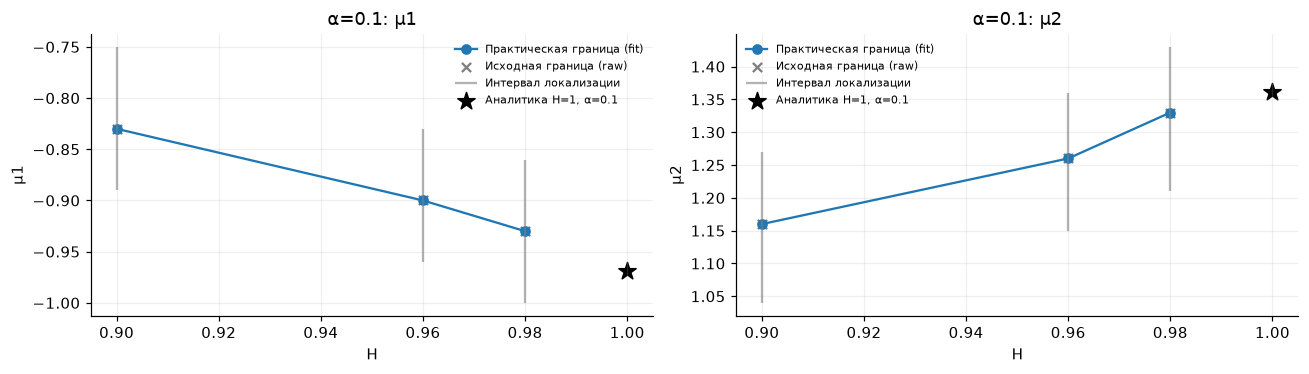

In [7]:
boundary_rows = []
for alpha, frame in frames.items():
    for h in H_NEAR_ONE:
        matches = frame[np.isclose(frame.H, h)]
        if len(matches) != 1:
            raise ValueError(f"Ожидалась одна строка H={h}, alpha={alpha}")
        row = matches.iloc[0]
        eps_h1 = alpha * float(value_h1(0, N))
        own = epsilon_boundaries(N, eps_h1)
        for side in (1, 2):
            fit = row[f"mu{side}_fit"]
            benchmark = own[side-1]
            boundary_rows.append({
                "alpha": alpha, "H data": h, "side": side,
                "epsilon data": row.epsilon, "epsilon H=1": eps_h1,
                "raw": row[f"mu{side}_raw"], "fit": fit,
                "status": row[f"mu{side}_fit_status"],
                "low": row[f"mu{side}_low"], "high": row[f"mu{side}_high"],
                "H=1 same alpha": benchmark,
                "difference same alpha": fit-benchmark,
                "abs difference %": abs(fit-benchmark)/abs(benchmark)*100,
            })
boundary_comparison = pd.DataFrame(boundary_rows)
display(boundary_comparison.round(6))
save_table(boundary_comparison, "boundary_comparison")

fig, axes = plt.subplots(len(ALPHAS), 2, figsize=(12, 3.5*len(ALPHAS)), squeeze=False)
for i, alpha in enumerate(ALPHAS):
    subset = boundary_comparison[boundary_comparison.alpha.eq(alpha)]
    for side in (1, 2):
        view = subset[subset.side.eq(side)].sort_values("H data")
        ax = axes[i, side-1]
        ax.plot(view["H data"], view["fit"], "o-", label="Практическая граница (fit)")
        ax.scatter(view["H data"], view["raw"], marker="x", color="gray", label="Исходная граница (raw)")
        valid = np.isfinite(view.low) & np.isfinite(view.high)
        ax.vlines(view.loc[valid, "H data"], view.loc[valid, "low"],
                  view.loc[valid, "high"], color="gray", alpha=.6, label="Интервал локализации")
        unconfirmed = view.status.ne("fitted")
        if unconfirmed.any():
            ax.scatter(view.loc[unconfirmed, "H data"], view.loc[unconfirmed, "fit"],
                       s=90, facecolors="none", edgecolors="red", label="Без подтверждённого интервала")
        ax.scatter([1.], [view["H=1 same alpha"].iloc[0]], marker="*", s=140,
                   color="black", label="Аналитика H=1, α=0.1")
        ax.set(title=f"α={alpha:g}: μ{side}", xlabel="H", ylabel=f"μ{side}")
        ax.legend(fontsize=7)
fig.tight_layout()
save_figure(fig, "boundary_comparison")
plt.show()